<a href="https://colab.research.google.com/github/arbialafkari/a/blob/main/Copy_of_preProsessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install emoji==1.7.0
!pip install Sastrawi

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.4/175.4 kB 3.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for emoji: filename=emoji-1.7.0-py3-none-any.whl size=171033 sha256=9136b9e8fff2c86cfb9b013af116e7e3963c51583bc19bc74c87b1b3c0471671
  Stored in directory: /root/.cache/pip/wheels/31/8a/8c/315c9e5d7773f74b33d5ed33f075b49c6eaeb7cedbb86e2cf8
Successfully built emoji
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 3.4 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import re
# import emoji
# import Sastrawi
import nltk
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout, Input, Flatten


In [ ]:
!gdown 1PRPiJpFwQ21N7qR4CrjuMGwWtRqonzQ8

Downloading...
From: https://drive.google.com/uc?id=1PRPiJpFwQ21N7qR4CrjuMGwWtRqonzQ8
To: /content/data latih - Sheet1 - data latih - Sheet1.csv
100% 57.4k/57.4k [00:00<00:00, 56.0MB/s]


In [ ]:
df = pd.read_csv("data latih - Sheet1 - data latih - Sheet1.csv")
df.head()

,text,timestamp,label
0,siang lah sepi mbak,2024-01-21T05:55:07.000Z,1
1,@ratudewa atau pejabat instansi terkait. tolon...,2024-01-21T06:19:52.000Z,3
2,Jln di Palembang ni dikuasai preman. sekendakn...,2024-01-21T10:39:50.000Z,3
3,@om_aye_flamboyand hehe....mainlah sesekali ke...,2024-01-24T01:31:18.000Z,3
4,Alhamdullillah sepi lemak lah itu min. kito li...,2023-12-26T07:52:58.000Z,1


In [ ]:
# Mengekstrak teks dan label
texts = df['text'].values
timestamp = df['timestamp'].values
labels = df['label'].values


#DATA CLEANING

In [ ]:
!pip install spacy
!python -m spacy download xx_ent_wiki_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 45.8 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('xx_ent_wiki_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import re
import emoji

def clean_text(text):
    if isinstance(text, str):  # Pastikan input adalah string
        text = re.sub("@[\w.]+", "", text)  # Hapus mention
        text = emoji.replace_emoji(text, replace="")  # Hapus emoji
        text = re.sub("#\w+", "", text)  # Hapus hashtag
        text = re.sub("http[s]?://\S+", "", text)  # Hapus URL
        text = text.strip()  # Hapus whitespace di awal dan akhir teks
        text = re.sub("\s+", " ", text)  # Hapus whitespace ekstra di tengah teks
        text = re.sub('[%s]' % re.escape("""!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~"""), ' ', text)  # Hapus simbol
        text = re.sub('\d+|[,!.]', '', text)  # Hapus angka dan tanda baca dari teks
        text = re.sub(r'\b\d+\S*', '', text)  # Hapus kata yang mulai dengan angka
        text = re.sub(r'(.)\1+', r'\1', text)  # Menghilangkan duplikasi huruf yang berurutan
    return text

df['cleaned'] = df['text'].apply(clean_text)


In [ ]:
df['text'] = df['text'].astype(str)
df['cleaned'] = df['text'].apply(clean_text)


In [ ]:
df_subset = df[['text', 'cleaned']]
df_subset

,text,cleaned
0,siang lah sepi mbak,siang lah sepi mbak
1,@ratudewa atau pejabat instansi terkait. tolon...,atau pejabat instansi terkait tolong dibantu u...
2,Jln di Palembang ni dikuasai preman. sekendakn...,Jln di Palembang ni dikuasai preman sekendakny...
3,@om_aye_flamboyand hehe....mainlah sesekali ke...,hehe mainlah sesekali ke pasar jgn ke mal aja ...
4,Alhamdullillah sepi lemak lah itu min. kito li...,Alhamdulilah sepi lemak lah itu min kito libur...
...,...,...
523,Pagi td katek contraflow tp alhamdulillah lanc...,Pagi td katek contraflow tp alhamdulilah lanca...
524,Jalan lancar dibikin macet.......jalan macet m...,Jalan lancar dibikin macet jalan macet malah d...
525,#ERROR!,
526,#ERROR!,


In [ ]:
df.shape

(528, 4)

#CASE FOLDING

In [ ]:
df["lower"] = df["cleaned"].apply(lambda x: x.lower()) # ubah semua huruf menjadi huruf kecil

In [ ]:
df_subset = df[['cleaned', 'lower']]
df_subset

,cleaned,lower
0,siang lah sepi mbak,siang lah sepi mbak
1,atau pejabat instansi terkait tolong dibantu u...,atau pejabat instansi terkait tolong dibantu u...
2,Jln di Palembang ni dikuasai preman sekendakny...,jln di palembang ni dikuasai preman sekendakny...
3,hehe mainlah sesekali ke pasar jgn ke mal aja ...,hehe mainlah sesekali ke pasar jgn ke mal aja ...
4,Alhamdulilah sepi lemak lah itu min kito libur...,alhamdulilah sepi lemak lah itu min kito libur...
...,...,...
523,Pagi td katek contraflow tp alhamdulilah lanca...,pagi td katek contraflow tp alhamdulilah lanca...
524,Jalan lancar dibikin macet jalan macet malah d...,jalan lancar dibikin macet jalan macet malah d...
525,,
526,,


#STEMMING

In [ ]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
factory = StemmerFactory()
stemmer = factory.create_stemmer()

# Asumsikan df adalah dataframe yang berisi data teks yang sudah di case folding
# Asumsikan kolom lower adalah kolom yang berisi data teks yang sudah di case folding
# Buat kolom baru untuk menyimpan hasil stemming
df['stemmed'] = df['lower'].apply(stemmer.stem)

In [ ]:
df_subset = df[['lower', 'stemmed']]
df_subset

,lower,stemmed
0,siang lah sepi mbak,siang lah sepi mbak
1,atau pejabat instansi terkait tolong dibantu u...,atau jabat instansi kait tolong bantu untuk te...
2,jln di palembang ni dikuasai preman sekendakny...,jln di palembang ni asai preman sekendaknyo be...
3,hehe mainlah sesekali ke pasar jgn ke mal aja ...,hehe main sekal ke pasar jgn ke mal aja kalo g...
4,alhamdulilah sepi lemak lah itu min kito libur...,alhamdulilah sepi lemak lah itu min kito libur...
...,...,...
523,pagi td katek contraflow tp alhamdulilah lanca...,pagi td katek contraflow tp alhamdulilah lanca...
524,jalan lancar dibikin macet jalan macet malah d...,jalan lancar bikin macet jalan macet malah bik...
525,,
526,,


#TOKENISASI DAN STOPWORD

In [ ]:
from nltk.tokenize import word_tokenize
nltk.download('punkt_tab')
df["tokenized"] = df["stemmed"].apply(word_tokenize)

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [ ]:
from nltk.corpus import stopwords
nltk.download('stopwords')

stop_words = set(stopwords.words('indonesian'))

# Menambahkan stopword kustom
# custom_stopwords = ['min','cak', 'd', 'ya', 'aja']
# stop_words = stop_words.union(custom_stopwords)
df['tokenized'].replace('', np.nan, inplace=True) # ganti cell kosong dengan np.nan
df.dropna(subset=['tokenized'], inplace=True) # hapus baris dengan np.nan di kolom 'text
df["stopwords"] = df["tokenized"].apply(lambda tokens: [token for token in tokens if token not in stop_words])

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
<ipython-input-18-6a8ae83a3c3d>:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['tokenized'].replace('', np.nan, inplace=True) # ganti cell kosong dengan np.nan


In [ ]:
stop_words

{'ada',
 'adalah',
 'adanya',
 'adapun',
 'agak',
 'agaknya',
 'agar',
 'akan',
 'akankah',
 'akhir',
 'akhiri',
 'akhirnya',
 'aku',
 'akulah',
 'amat',
 'amatlah',
 'anda',
 'andalah',
 'antar',
 'antara',
 'antaranya',
 'apa',
 'apaan',
 'apabila',
 'apakah',
 'apalagi',
 'apatah',
 'artinya',
 'asal',
 'asalkan',
 'atas',
 'atau',
 'ataukah',
 'ataupun',
 'awal',
 'awalnya',
 'bagai',
 'bagaikan',
 'bagaimana',
 'bagaimanakah',
 'bagaimanapun',
 'bagi',
 'bagian',
 'bahkan',
 'bahwa',
 'bahwasanya',
 'baik',
 'bakal',
 'bakalan',
 'balik',
 'banyak',
 'bapak',
 'baru',
 'bawah',
 'beberapa',
 'begini',
 'beginian',
 'beginikah',
 'beginilah',
 'begitu',
 'begitukah',
 'begitulah',
 'begitupun',
 'bekerja',
 'belakang',
 'belakangan',
 'belum',
 'belumlah',
 'benar',
 'benarkah',
 'benarlah',
 'berada',
 'berakhir',
 'berakhirlah',
 'berakhirnya',
 'berapa',
 'berapakah',
 'berapalah',
 'berapapun',
 'berarti',
 'berawal',
 'berbagai',
 'berdatangan',
 'beri',
 'berikan',
 'berikut'

In [ ]:
df_subset = df[['tokenized', 'stopwords']]
df_subset

,tokenized,stopwords
0,"[siang, lah, sepi, mbak]","[siang, sepi, mbak]"
1,"[atau, jabat, instansi, kait, tolong, bantu, u...","[jabat, instansi, kait, tolong, bantu, tertib,..."
2,"[jln, di, palembang, ni, asai, preman, sekenda...","[jln, palembang, ni, asai, preman, sekendaknyo..."
3,"[hehe, main, sekal, ke, pasar, jgn, ke, mal, a...","[hehe, main, sekal, pasar, jgn, mal, aja, kalo..."
4,"[alhamdulilah, sepi, lemak, lah, itu, min, kit...","[alhamdulilah, sepi, lemak, min, kito, libur, ..."
...,...,...
523,"[pagi, td, katek, contraflow, tp, alhamdulilah...","[pagi, td, katek, contraflow, tp, alhamdulilah..."
524,"[jalan, lancar, bikin, macet, jalan, macet, ma...","[jalan, lancar, bikin, macet, jalan, macet, bi..."
525,[],[]
526,[],[]


#NORMALISASI

In [ ]:
!curl -LJO "https://drive.google.com/uc?id=1--WuwOcDmdLMxGGWTvUAS40JWYCTr1iE"

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 3035k  100 3035k    0     0   889k      0  0:00:03  0:00:03 --:--:--  975k


In [ ]:
!curl -LJO "https://drive.google.com/uc?id=1--WuwOcDmdLMxGGWTvUAS40JWYCTr1iE" # Download the file

import pandas as pd # Import pandas library
normalization_word = pd.read_csv("colloquial-indonesian-lexicon.csv") # Read the downloaded file. Removed '/content/' since the file is downloaded in the current directory.
normalization_word_dict = {}

for index, row in normalization_word.iterrows():
  if row[0] not in normalization_word_dict:
    normalization_word_dict[row[0]] = row[1]

def normalization(document):
  return [normalization_word_dict[term] if term in normalization_word_dict else term for term in document]

df['normalization'] = df['stopwords'].apply(normalization)

from nltk.tokenize.treebank import TreebankWordDetokenizer # Import the TreebankWordDetokenizer
df['normalization'] = df['normalization'].apply(lambda x: TreebankWordDetokenizer().detokenize(x))

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
  0     0    0     0    0     0      0      0 --:--:--  0:00:03 --:--:--     0Warning: Failed to create the file colloquial-indonesian-lexicon.csv: File 
  0     0    0     0    0     0      0      0 --:--:--  0:00:03 --:--:--     0
curl: (23) Failed writing header


<ipython-input-22-e047a6ad35b0>:8: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if row[0] not in normalization_word_dict:
<ipython-input-22-e047a6ad35b0>:9: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  normalization_word_dict[row[0]] = row[1]


In [ ]:
df_subset = df[['stopwords', 'normalization']]
df_subset

,stopwords,normalization
0,"[siang, sepi, mbak]",siang sepi mbak
1,"[jabat, instansi, kait, tolong, bantu, tertib,...",jabat instansi kait tolong bantu tertib dagang...
2,"[jln, palembang, ni, asai, preman, sekendaknyo...",jalan palembang ini asai preman sekendaknyo sa...
3,"[hehe, main, sekal, pasar, jgn, mal, aja, kalo...",hehe main sekal pasar jangan mal saja kalo eng...
4,"[alhamdulilah, sepi, lemak, min, kito, libur, ...",alhamdulilah sepi lemak min kito libur sat bga...
...,...,...
523,"[pagi, td, katek, contraflow, tp, alhamdulilah...",pagi tadi tidak ada contraflow tapi alhamdulil...
524,"[jalan, lancar, bikin, macet, jalan, macet, bi...",jalan lancar bikin macet jalan macet bikin mac...
525,[],
526,[],


In [ ]:
!gdown 1hkqd8kOY_qhGNmegwMMrUHOoyWOwcfJ2

Downloading...
From: https://drive.google.com/uc?id=1hkqd8kOY_qhGNmegwMMrUHOoyWOwcfJ2
To: /content/hasil_preprocessedFIX.csv
100% 335k/335k [00:00<00:00, 84.4MB/s]


In [ ]:
df.to_csv('hasil_preprocessedFIX.csv', index=False)

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv("/content/hasil_preprocessedFIX.csv")

In [ ]:
df_subset = df[['cleaned', 'lower', 'stemmed', 'tokenized', 'stopwords', 'normalization']]
df_subset

,cleaned,lower,stemmed,tokenized,stopwords,normalization
0,siang lah sepi mbak,siang lah sepi mbak,siang lah sepi mbak,"['siang', 'lah', 'sepi', 'mbak']","['siang', 'sepi', 'mbak']",siang sepi mbak
1,atau pejabat instansi terkait tolong dibantu u...,atau pejabat instansi terkait tolong dibantu u...,atau jabat instansi kait tolong bantu untuk te...,"['atau', 'jabat', 'instansi', 'kait', 'tolong'...","['jabat', 'instansi', 'kait', 'tolong', 'bantu...",jabat instansi kait tolong bantu tertib dagang...
2,Jln di Palembang ni dikuasai preman sekendakny...,jln di palembang ni dikuasai preman sekendakny...,jln di palembang ni asai preman sekendaknyo be...,"['jln', 'di', 'palembang', 'ni', 'asai', 'prem...","['jln', 'palembang', 'ni', 'asai', 'preman', '...",jalan palembang ini asai preman sekendaknyo sa...
3,hehe mainlah sesekali ke pasar jgn ke mal aja ...,hehe mainlah sesekali ke pasar jgn ke mal aja ...,hehe main sekal ke pasar jgn ke mal aja kalo g...,"['hehe', 'main', 'sekal', 'ke', 'pasar', 'jgn'...","['hehe', 'main', 'sekal', 'pasar', 'jgn', 'mal...",hehe main sekal pasar jangan mal saja kalo eng...
4,Alhamdulilah sepi lemak lah itu min kito libur...,alhamdulilah sepi lemak lah itu min kito libur...,alhamdulilah sepi lemak lah itu min kito libur...,"['alhamdulilah', 'sepi', 'lemak', 'lah', 'itu'...","['alhamdulilah', 'sepi', 'lemak', 'min', 'kito...",alhamdulilah sepi lemak min kito libur sat bga...
...,...,...,...,...,...,...
523,Pagi td katek contraflow tp alhamdulilah lanca...,pagi td katek contraflow tp alhamdulilah lanca...,pagi td katek contraflow tp alhamdulilah lanca...,"['pagi', 'td', 'katek', 'contraflow', 'tp', 'a...","['pagi', 'td', 'katek', 'contraflow', 'tp', 'a...",pagi tadi tidak ada contraflow tapi alhamdulil...
524,Jalan lancar dibikin macet jalan macet malah d...,jalan lancar dibikin macet jalan macet malah d...,jalan lancar bikin macet jalan macet malah bik...,"['jalan', 'lancar', 'bikin', 'macet', 'jalan',...","['jalan', 'lancar', 'bikin', 'macet', 'jalan',...",jalan lancar bikin macet jalan macet bikin mac...
525,Kalau di depan pasar KM tertib dan dijaga ole...,kalau di depan pasar km tertib dan dijaga ole...,kalau di depan pasar km tertib dan jaga oleh t...,"['kalau', 'di', 'depan', 'pasar', 'km', 'terti...","['pasar', 'km', 'tertib', 'jaga', 'tugas', 'te...",pasar kamu tertib jaga tugas termasui depn muh...
526,kalau semua orang perginya seperti Tante baga...,kalau semua orang perginya seperti tante baga...,kalau semua orang pergi seperti tante bagaiman...,"['kalau', 'semua', 'orang', 'pergi', 'seperti'...","['orang', 'pergi', 'tante', 'macet', 'jala', '...",orang pergi tante macet jala mangkanya cari ti...


In [ ]:
df.dropna(inplace = True)

In [ ]:
df

,text,timestamp,label,cleaned,lower,stemmed,tokenized,stopwords,normalization
0,siang lah sepi mbak,2024-01-21T05:55:07.000Z,1,siang lah sepi mbak,siang lah sepi mbak,siang lah sepi mbak,"['siang', 'lah', 'sepi', 'mbak']","['siang', 'sepi', 'mbak']",siang sepi mbak
1,"@ratudewa atau pejabat instansi terkait, tolon...",2024-01-21T06:19:52.000Z,3,atau pejabat instansi terkait tolong dibantu u...,atau pejabat instansi terkait tolong dibantu u...,atau jabat instansi kait tolong bantu untuk te...,"['atau', 'jabat', 'instansi', 'kait', 'tolong'...","['jabat', 'instansi', 'kait', 'tolong', 'bantu...",jabat instansi kait tolong bantu tertib dagang...
2,"Jln di Palembang ni dikuasai preman, sekendakn...",2024-01-21T10:39:50.000Z,3,Jln di Palembang ni dikuasai preman sekendakny...,jln di palembang ni dikuasai preman sekendakny...,jln di palembang ni asai preman sekendaknyo be...,"['jln', 'di', 'palembang', 'ni', 'asai', 'prem...","['jln', 'palembang', 'ni', 'asai', 'preman', '...",jalan palembang ini asai preman sekendaknyo sa...
3,@om_aye_flamboyand hehe....mainlah sesekali ke...,2024-01-24T01:31:18.000Z,3,hehe mainlah sesekali ke pasar jgn ke mal aja ...,hehe mainlah sesekali ke pasar jgn ke mal aja ...,hehe main sekal ke pasar jgn ke mal aja kalo g...,"['hehe', 'main', 'sekal', 'ke', 'pasar', 'jgn'...","['hehe', 'main', 'sekal', 'pasar', 'jgn', 'mal...",hehe main sekal pasar jangan mal saja kalo eng...
4,"Alhamdullillah sepi lemak lah itu min, kito li...",2023-12-26T07:52:58.000Z,1,Alhamdulilah sepi lemak lah itu min kito libur...,alhamdulilah sepi lemak lah itu min kito libur...,alhamdulilah sepi lemak lah itu min kito libur...,"['alhamdulilah', 'sepi', 'lemak', 'lah', 'itu'...","['alhamdulilah', 'sepi', 'lemak', 'min', 'kito...",alhamdulilah sepi lemak min kito libur sat bga...
...,...,...,...,...,...,...,...,...,...
523,Pagi td katek contraflow tp alhamdulillah lanc...,"7/23/2024, 4:29:59 PM",1,Pagi td katek contraflow tp alhamdulilah lanca...,pagi td katek contraflow tp alhamdulilah lanca...,pagi td katek contraflow tp alhamdulilah lanca...,"['pagi', 'td', 'katek', 'contraflow', 'tp', 'a...","['pagi', 'td', 'katek', 'contraflow', 'tp', 'a...",pagi tadi tidak ada contraflow tapi alhamdulil...
524,Jalan lancar dibikin macet.......jalan macet m...,"7/23/2024, 6:10:58 PM",1,Jalan lancar dibikin macet jalan macet malah d...,jalan lancar dibikin macet jalan macet malah d...,jalan lancar bikin macet jalan macet malah bik...,"['jalan', 'lancar', 'bikin', 'macet', 'jalan',...","['jalan', 'lancar', 'bikin', 'macet', 'jalan',...",jalan lancar bikin macet jalan macet bikin mac...
525,"=""Kalau di depan pasar KM 5 tertib dan dijaga ...","7/23/2024, 11:18:39 PM",1,Kalau di depan pasar KM tertib dan dijaga ole...,kalau di depan pasar km tertib dan dijaga ole...,kalau di depan pasar km tertib dan jaga oleh t...,"['kalau', 'di', 'depan', 'pasar', 'km', 'terti...","['pasar', 'km', 'tertib', 'jaga', 'tugas', 'te...",pasar kamu tertib jaga tugas termasui depn muh...
526,"=""@elistinadewi3 kalau semua orang perginya se...","7/24/2024, 7:58:00 PM",1,kalau semua orang perginya seperti Tante baga...,kalau semua orang perginya seperti tante baga...,kalau semua orang pergi seperti tante bagaiman...,"['kalau', 'semua', 'orang', 'pergi', 'seperti'...","['orang', 'pergi', 'tante', 'macet', 'jala', '...",orang pergi tante macet jala mangkanya cari ti...


In [ ]:
df['label'] -= 1

In [ ]:
df['label'].unique()

array([0, 2, 1])

In [ ]:
from transformers import TFBertForSequenceClassification, AutoTokenizer

# Load a pre-trained model (e.g., BERT)
model_name = "indolem/indobert-base-uncased"
# base_model = TFBertForSequenceClassification.from_pretrained(model_name, from_pt=True, num_labels = 3)
tokenizer = AutoTokenizer.from_pretrained(model_name)

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/234k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [ ]:
tokenized_data = tokenizer(
    list(df['normalization']),
    max_length=128,
    padding='max_length',
    truncation=True,
    return_tensors="tf"
    )


In [ ]:
print(tokenized_data["input_ids"])

tf.Tensor(
[[    3  3909 10369 ...     0     0     0]
 [    3  3268  1481 ...     0     0     0]
 [    3  2050  7201 ...     0     0     0]
 ...
 [    3  2820  3162 ...     0     0     0]
 [    3  1646  3693 ...     0     0     0]
 [    3  2695  1572 ...     0     0     0]], shape=(526, 128), dtype=int32)


In [ ]:
import numpy as np
len(np.unique(tokenized_data["input_ids"]))

1524

In [ ]:
model = Sequential()
model.add(Input(shape=(128,1)))
model.add(Embedding(1525,64))
model.add(Flatten())
model.add(Dense(512,activation = 'relu'))
model.add(Dense(256,activation = 'relu'))
model.add(Dense(128,activation = 'relu'))
model.add(Dense(64,activation = 'relu'))
model.add(Dense(3, activation = "softmax"))


In [ ]:
model.compile(optimizer = 'adam', loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

In [ ]:
model.fit(tokenized_data['input_ids'],df['label'], epochs = 10, validation_split = 0.2)

Epoch 1/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 11s 286ms/step - accuracy: 0.0543 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 2/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0302 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 3/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0318 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 4/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0362 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 5/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0214 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 6/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0248 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 7/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0328 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 8/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0344 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch

In [ ]:
print(len(base_model.layers))

3


In [ ]:
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.models import Model
import tensorflow as tf

# Freeze the base model if you don't want to fine-tune the transformer itself
base_model.trainable = True
# base_model.layers[:-1].trainable = True
base_model.compile(optimizer='adam', metrics = ['accuracy'])

# Input layer
# input_ids = Input(shape=(512,), dtype=tf.int32, name="input_ids")
# attention_mask = Input(shape=(512,), dtype=tf.int32, name="attention_mask")
# print(type(input_ids))
# print(type(attention_mask))

# # Transformer base
# transformer_output = base_model(input_ids, attention_mask)
# hidden_state = transformer_output.last_hidden_state

# # Custom layers
# x = Dense(256, activation="relu")(hidden_state[:, 0, :])  # Use [CLS] token embedding
# x = Dropout(0.3)(x)
# output = Dense(1, activation="sigmoid")(x)  # Example: Binary classification

# # Define the model
# model = Model(inputs=[input_ids, attention_mask], outputs=output)


In [ ]:
for text in df['normalization']:
    if type(text) != str:
        print(text,type(text))

In [ ]:
def encode_data(texts, labels, tokenizer, max_length=128):
    encodings = tokenizer(
        texts,
        max_length=max_length,
        padding='max_length',
        truncation=True,
        return_tensors="tf"
    )
    return tf.data.Dataset.from_tensor_slices((
        {
            "input_ids": encodings["input_ids"],
            "attention_mask": encodings["attention_mask"]
        },
        labels
    ))
dataset = encode_data(list(df['normalization']),list(df['label']),tokenizer).shuffle(buffer_size=len(df['normalization']), seed=42)
# encoded_data = encode_data()
dataset_size = len(df['normalization'])
train_size = int(0.8 * dataset_size)

# Split the dataset
train_dataset = dataset.take(train_size)  # First 80%
test_dataset = dataset.skip(train_size)   # Remaining 20%

# Batch the datasets
train_dataset = train_dataset.batch(2)
test_dataset = test_dataset.batch(2)
# dataset = encoded_data.shuffle(10).batch(2)

In [ ]:
his

In [ ]:
encoded_data

<_TensorSliceDataset element_spec=({'input_ids': TensorSpec(shape=(128,), dtype=tf.int32, name=None), 'attention_mask': TensorSpec(shape=(128,), dtype=tf.int32, name=None)}, TensorSpec(shape=(), dtype=tf.int32, name=None))>

In [ ]:
history = base_model.fit(train_dataset,validation_data = test_dataset, epochs = 10, validation_split = 0.2)

Epoch 1/10
210/210 [==============================] - 107s 137ms/step - loss: 1.1565 - accuracy: 0.6286 - val_loss: 0.8834 - val_accuracy: 0.7264
Epoch 2/10
210/210 [==============================] - 21s 100ms/step - loss: 0.8072 - accuracy: 0.6833 - val_loss: 0.6409 - val_accuracy: 0.7736
Epoch 3/10
210/210 [==============================] - 21s 100ms/step - loss: 0.8985 - accuracy: 0.6286 - val_loss: 0.7266 - val_accuracy: 0.7358
Epoch 4/10
210/210 [==============================] - 21s 100ms/step - loss: 0.7835 - accuracy: 0.6857 - val_loss: 0.7784 - val_accuracy: 0.7075
Epoch 5/10
210/210 [==============================] - 22s 104ms/step - loss: 0.8365 - accuracy: 0.6762 - val_loss: 0.7570 - val_accuracy: 0.7453
Epoch 6/10
210/210 [==============================] - 20s 97ms/step - loss: 0.8695 - accuracy: 0.6881 - val_loss: 0.6903 - val_accuracy: 0.8019
Epoch 7/10
210/210 [==============================] - 22s 104ms/step - loss: 0.9605 - accuracy: 0.6143 - val_loss: 0.8723 - val_ac

In [ ]:
import matplotlib.pyplot as plt


# TF IDF


In [ ]:
# Import library yang dibutuhkan
import math
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

# Membaca file CSV
df = pd.read_csv('/content/hasil_preprocessedFIX.csv')

In [ ]:
# Pastikan kolom teks bernama 'text', jika namanya berbeda, ganti sesuai CSV
docs = df['normalization'].tolist()

# Menghapus nilai NaN dari list docs
# NaN values cannot be processed by the split function
docs = [doc for doc in docs if isinstance(doc, str)]

In [ ]:
# Fungsi untuk menghitung TF (Term Frequency)
def compute_tf(doc):
    tf_dict = {}
    words = doc.split()
    total_words = len(words)
    for word in words:
        tf_dict[word] = tf_dict.get(word, 0) + 1
    for word in tf_dict:
        tf_dict[word] = tf_dict[word] / total_words
    return tf_dict

In [ ]:
# Fungsi untuk menghitung IDF (Inverse Document Frequency)
def compute_idf(docs):
    idf_dict = {}
    total_docs = len(docs)
    all_words = set([word for doc in docs for word in doc.split()])
    for word in all_words:
        count = sum([1 for doc in docs if word in doc.split()])
        idf_dict[word] = math.log(total_docs / count)
    return idf_dict

In [ ]:
# Fungsi untuk menghitung TF-IDF
def compute_tfidf(tf, idf):
    tfidf_dict = {}
    for word, tf_val in tf.items():
        tfidf_dict[word] = tf_val * idf.get(word, 0)
    return tfidf_dict

In [ ]:
# Menghitung TF untuk setiap dokumen
tf_list = []
for doc in docs:
    tf_list.append(compute_tf(doc))

# Menghitung IDF dari semua dokumen
idf_dict = compute_idf(docs)

In [ ]:
# Menghitung IDF untuk semua dokumen di luar loop
idf_dict = compute_idf(docs)

# Menampilkan hasil TF-IDF
for i, tf in enumerate(tf_list):
    print(f"Dokumen {i + 1} - TF:")
    print(tf)
    print(f"Dokumen {i + 1} - IDF:")
    print(idf_dict)  # Menggunakan idf_dict yang dihitung di luar loop

    tfidf_dict = compute_tfidf(tf, idf_dict)
    print(f"Dokumen {i + 1} - TF-IDF:")
    print(tfidf_dict)
    print("-" * 50)

Dokumen 1 - TF:
{'siang': 0.3333333333333333, 'sepi': 0.3333333333333333, 'mbak': 0.3333333333333333}
Dokumen 1 - IDF:
{'sebelum': 6.2422232654551655, 'sama': 4.45046379622711, 'melompong': 6.2422232654551655, 'tumpang': 5.54907608489522, 'p': 6.2422232654551655, 'dag': 5.1436109767870555, 'bangun': 4.0449986881189455, 'terhadang': 6.2422232654551655, 'kuasa': 6.2422232654551655, 'titik': 4.296313116399852, 'coba': 4.45046379622711, 'note': 6.2422232654551655, 'acak': 6.2422232654551655, 'rebut': 6.2422232654551655, 'lantas': 6.2422232654551655, 'budak': 4.855928904335275, 'bgwe': 5.54907608489522, 'tambah': 5.54907608489522, 'pentas': 6.2422232654551655, 'produktif': 6.2422232654551655, 'nyantai': 6.2422232654551655, 'ulah': 6.2422232654551655, 'alternativ': 6.2422232654551655, 'area': 6.2422232654551655, 'kepalang': 6.2422232654551655, 'insya': 4.632785353021065, 'korban': 6.2422232654551655, 'mahasiswa': 6.2422232654551655, 'galak': 4.296313116399852, 'jakabaring': 4.855928904335275

In [ ]:
import pandas as pd

# ... (Your existing code to calculate TF-IDF) ...

# Create a list to store the data
data = []
for i, tf in enumerate(tf_list):
    for word, tf_val in tf.items():
        tfidf_val = tf_val * idf_dict.get(word, 0)
        data.append([i + 1, word, tf_val, idf_dict.get(word, 0), tfidf_val])

# Create a Pandas DataFrame
df_tfidf = pd.DataFrame(data, columns=['Document', 'Word', 'TF', 'IDF', 'TF-IDF'])

# Save the DataFrame to a CSV file
df_tfidf.to_csv('tfidf_results.csv', index=False)

In [ ]:
import pandas as pd

# Change the file path if necessary
df_tfidf = pd.read_csv('tfidf_results.csv')

total_tf = df_tfidf['TF'].sum()
unique_words_idf = df_tfidf[['Word', 'IDF']].drop_duplicates()
total_tfidf = df_tfidf['TF-IDF'].sum()

print("Total TF untuk keseluruhan dokumen:", total_tf)
print("\nIDF untuk setiap kata unik:\n", unique_words_idf)
print("\nTotal TF-IDF untuk keseluruhan dokumen:", total_tfidf)

Total TF untuk keseluruhan dokumen: 513.9999999999999

IDF untuk setiap kata unik:
            Word       IDF
0         siang  3.939638
1          sepi  4.450464
2          mbak  4.296313
3         jabat  5.549076
4      instansi  6.242223
...         ...       ...
4825    dengeri  6.242223
4826    omomgan  6.242223
4834      mreja  6.242223
4835     jadika  6.242223
4838  dibersike  6.242223

[1344 rows x 2 columns]

Total TF-IDF untuk keseluruhan dokumen: 1776.7265544888637


In [ ]:
df_tfidf

,Document,Word,TF,IDF,TF-IDF
0,1,siang,0.333333,3.939638,1.313213
1,1,sepi,0.333333,4.450464,1.483488
2,1,mbak,0.333333,4.296313,1.432104
3,2,jabat,0.052632,5.549076,0.292057
4,2,instansi,0.052632,6.242223,0.328538
...,...,...,...,...,...
4836,514,parkir,0.035714,3.023347,0.107977
4837,514,coba,0.035714,4.450464,0.158945
4838,514,dibersike,0.035714,6.242223,0.222937
4839,514,jalan,0.035714,1.532693,0.054739


In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import joblib

In [ ]:
# Baca data yang telah diproses
data = pd.read_csv('/content/hasil_preprocessedFIX.csv')  # Asumsikan file CSV bernama 'processed_data.csv'
texts = data['normalization']  # Asumsikan kolom teks bernama 'text'
labels = data['label']  # Asumsikan kolom label bernama 'label'

In [ ]:
# TF-IDF Vectorization
vectorizer = TfidfVectorizer()
# drop rows with nan values in 'texts'
X = vectorizer.fit_transform(texts.dropna())
y = labels[texts.notna()] # use boolean indexing to adjust labels accordingly

#RECURRENT NEURAL NETWORK

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Baca data yang telah diproses
data = pd.read_csv('/content/hasil_preprocessedFIX.csv')
texts = data['normalization'].astype(str)  # Convert the 'normalization' column to string type
labels = data['label']

# Label Encoding
le = LabelEncoder()
y = le.fit_transform(labels)

# Tokenisasi teks
tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(texts)
X = tokenizer.texts_to_sequences(texts)

# Padding sequences agar semua data memiliki panjang yang sama
maxlen = 100  # Maksimal panjang urutan, bisa diubah sesuai kebutuhan
X = pad_sequences(X, padding='post', maxlen=maxlen)

# Bagi data menjadi data pelatihan dan data pengujian
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Membangun model RNN dengan SimpleRNN
model = Sequential()
model.add(Embedding(input_dim=5000, output_dim=128, input_length=maxlen))
model.add(SimpleRNN(units=128, dropout=0.2))  # Using SimpleRNN instead of LSTM
model.add(Dense(1, activation='sigmoid'))

# Kompilasi model
model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

# Latih model
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.2)

# Evaluasi model
y_pred = (model.predict(X_test) > 0.5).astype("int32")  # Convert probabilities to binary predictions
# Convert le.classes_ to a list of strings
target_names = [str(cls) for cls in le.classes_]
print(classification_report(y_test, y_pred, target_names=target_names))
print("Accuracy:", accuracy_score(y_test, y_pred))

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 79ms/step - accuracy: 0.0788 - loss: -0.2753 - val_accuracy: 0.0118 - val_loss: -2.7351
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.0268 - loss: -3.3331 - val_accuracy: 0.0118 - val_loss: -4.6226
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.0109 - loss: -5.4013 - val_accuracy: 0.0118 - val_loss: -5.9394
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.0113 - loss: -6.4659 - val_accuracy: 0.0118 - val_loss: -6.9034
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.0261 - loss: -7.3389 - val_accuracy: 0.0118 - val_loss: -7.7506
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.0251 - loss: -8.4988 - val_accuracy: 0.0118 - val_loss: -8.4805
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.0174 - loss: -9.4904 - val_accuracy: 0.0118 - val_loss: -9.1873
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.0277 - loss: -10.7122 - val_accu

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


#__________________________

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout
from tensorflow.keras.optimizers import Adam

In [ ]:
# Baca data yang telah diproses
data = pd.read_csv('/content/hasil_preprocessedFIX.csv')
texts = data['normalization'].astype(str)  # Convert the 'normalization' column to string type
labels = data['label']

In [ ]:
# Label Encoding
le = LabelEncoder()
y = le.fit_transform(labels)

In [ ]:
# Tokenisasi teks
tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(texts)
X = tokenizer.texts_to_sequences(texts)

In [ ]:
# Baca data yang telah diproses
data = pd.read_csv('/content/hasil_preprocessedFIX.csv')
texts = data['normalization'].astype(str) # Convert the 'normalization' column to string type
labels = data['label']

# Label Encoding
le = LabelEncoder()
y = le.fit_transform(labels)

# Tokenisasi teks
tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(texts)
X = tokenizer.texts_to_sequences(texts)

In [ ]:
# Padding sequences agar semua data memiliki panjang yang sama
maxlen = 100  # Maksimal panjang urutan, bisa diubah sesuai kebutuhan
X = pad_sequences(X, padding='post', maxlen=maxlen)

In [ ]:
# Bagi data menjadi data pelatihan dan data pengujian
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
# Membangun model RNN dengan LSTM
model = Sequential()
model.add(Embedding(input_dim=5000, output_dim=128, input_length=maxlen))
model.add(LSTM(units=128, dropout=0.2, recurrent_dropout=0.2))
model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
# Kompilasi model
model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])


In [ ]:
# Latih model
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.2)


Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 203ms/step - accuracy: 0.0833 - loss: -0.0520 - val_accuracy: 0.0118 - val_loss: -3.3697
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 163ms/step - accuracy: 0.0203 - loss: -4.1779 - val_accuracy: 0.0118 - val_loss: -5.8171
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 166ms/step - accuracy: 0.0211 - loss: -7.1202 - val_accuracy: 0.0118 - val_loss: -7.2621
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 169ms/step - accuracy: 0.0163 - loss: -8.3695 - val_accuracy: 0.0118 - val_loss: -8.1727
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 273ms/step - accuracy: 0.0204 - loss: -9.5800 - val_accuracy: 0.0118 - val_loss: -8.9711
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 303ms/step - accuracy: 0.0310 - loss: -11.1678 - val_accuracy: 0.0118 - val_loss: -9.6851
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 188ms/step - accuracy: 0.0302 - loss: -11.0523 - val_accuracy: 0.0118 - val_loss: -10.3725
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 161ms/step - accuracy: 0.0189 - loss: -11.7280

data uji


4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 435ms/step


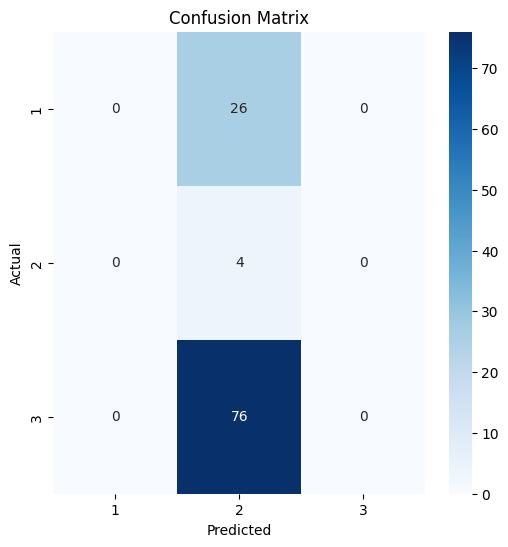

Akurasi: 0.03773584905660377
Laporan Klasifikasi:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00        26
           1       0.04      1.00      0.07         4
           2       0.00      0.00      0.00        76

    accuracy                           0.04       106
   macro avg       0.01      0.33      0.02       106
weighted avg       0.00      0.04      0.00       106



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generate predictions using your trained model
y_pred = model.predict(X_test)
# Convert the predicted probabilities to class labels (0 or 1)
y_pred = (y_pred > 0.5).astype(int)

# Menghitung Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Menampilkan Confusion Matrix
plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Print Akurasi dan Laporan Klasifikasi
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

In [ ]:
# Simpan model dan vectorizer
joblib.dump(model, 'trained_model.pkl')
joblib.dump(vectorizer, 'vectorizer.pkl')

['vectorizer.pkl']

In [ ]:
import pandas as pd
import joblib
import re
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
import nltk
nltk.download('stopwords')
nltk.download('punkt')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [ ]:
# Membaca data baru dari file CSV
data_new = pd.read_csv('/content/drive/MyDrive/sentiment analysis/fix/data uji - Sheet1 - data uji - Sheet1.csv')  # Asumsikan file CSV bernama 'new_data.csv'
texts_new = data_new['text']  # Asumsikan kolom teks bernama 'text'
labels_new = data_new['label']  # Asumsikan kolom label bernama 'label'

In [ ]:
# Memuat TfidfVectorizer dan model Naive Bayes yang telah dilatih
vectorizer = joblib.load('vectorizer.pkl')
model = joblib.load('trained_model.pkl')

In [ ]:
# Definisikan fungsi untuk membersihkan teks
def clean_text(text):
    # Menghapus karakter yang tidak diinginkan, misalnya HTML tags
    text = re.sub(r'<.*?>', '', text)
    # Menghapus tanda baca
    text = text.translate(str.maketrans('', '', string.punctuation))
    # Menghapus angka
    text = re.sub(r'\d+', '', text)
    # Menghapus spasi berlebih
    text = text.strip()
    text = re.sub(r'\s+', ' ', text)
    return text

# Definisikan fungsi preprocess_text
def preprocess_text(text):
    # Membersihkan teks
    text = clean_text(text)
    # Mengubah teks menjadi huruf kecil
    text = text.lower()
    # Tokenisasi
    words = word_tokenize(text)
    # Menghapus stop words
    stop_words = set(stopwords.words('indonesian'))
    words = [word for word in words if word not in stop_words]
    # Stemming
    stemmer = PorterStemmer()
    words = [stemmer.stem(word) for word in words]
    # Gabungkan kembali kata-kata menjadi teks
    text = ' '.join(words)
    return text

In [ ]:
# Preprocess teks baru
data_new_preprocessed = [preprocess_text(text) for text in texts_new]

In [ ]:
# Transformasi teks baru menjadi fitur TF-IDF
texts_new_features = vectorizer.transform(data_new_preprocessed)

In [ ]:
# Melakukan prediksi menggunakan model Naive Bayes yang telah dilatih
predictions = model.predict(texts_new_features)

6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 614ms/step


In [ ]:
# Menyimpan hasil prediksi ke file CSV baru
data_new['predicted_label'] = predictions
data_new.to_csv('predicted_results012.csv', index=False)
print("Prediksi telah disimpan ke 'predicted_results012.csv'")

Prediksi telah disimpan ke 'predicted_results012.csv'


In [ ]:
data_new

,text,timestamp,label,predicted_label
0,Apo lagi jalan sekip min sepi jalan,2023-12-26T07:04:34.000Z,1,1.0
1,Titik macet itu di depan alfurqon sm pintu mas...,2024-04-30T10:57:41.000Z,3,1.0
2,yg BUAT MACET *1. LAMPU MERAH ANK66. *2.KELUAR...,2024-04-30T12:12:17.000Z,3,1.0
3,SD Muhammadiyah yang belum lancar kalo bubar s...,2024-02-24T11:23:16.000Z,2,1.0
4,Bukan Musi 4 be yg macet tapi di sekip. iba . ...,2024-03-07T12:13:52.000Z,3,1.0
...,...,...,...,...
184,Saro konsumen kami.. ðŸ˜‚ðŸ˜‚.itu kan rekayasa...,"5/29/2024, 11:38:13 PM",1,1.0
185,Yang kearah ampera lancar.. Yang kearah bandar...,"7/22/2024, 12:07:06 PM",1,1.0
186,Besok tutup lagi bae pak belokan pasar palimo ...,"7/23/2024, 10:28:02 AM",1,1.0
187,Puteran pal 5 ditutup lancar jalan ðŸ‘ðŸ‘,"7/23/2024, 4:58:25 PM",1,1.0
